In [16]:
# === Library Setup ===
import pandas as pd
import re
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

In [17]:
# === Baca dan Preprocessing Data ===
df = pd.read_excel(r'D:\dirty work\all data.xlsx')

def clean_text(text):
    if pd.isna(text):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.replace('eoc', 'end of contract')
    text = text.replace('thd', 'terhadap')
    text = text.replace('ybs', 'yang bersangkutan')
    text = text.strip()
    return text

df['clean_text'] = df['Exit Interview'].apply(clean_text)

In [18]:
# Filter label
df = df.dropna(subset=['Reason Category'])
df['Reason Category'] = df['Reason Category'].astype(str).str.strip().str.upper()
df = df[df['Reason Category'].isin(['R', 'UR'])]


In [19]:
# Encode label
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['Reason Category'])

In [20]:
import joblib
joblib.dump(label_encoder, "label_encoder.pkl")

['label_encoder.pkl']

C:\Users\Titania\AppData\Local\Temp\ipykernel_13944\494106053.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_names, y=label_counts.values, palette='Set2')


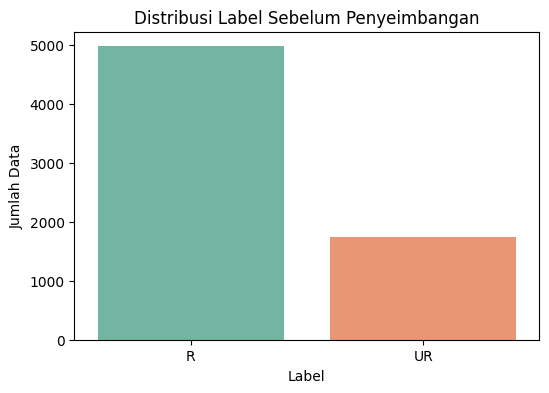

In [21]:
# Visualisasi distribusi awal
label_counts = df['label'].value_counts().sort_index()
label_names = label_encoder.inverse_transform(label_counts.index)
plt.figure(figsize=(6, 4))
sns.barplot(x=label_names, y=label_counts.values, palette='Set2')
plt.title("Distribusi Label Sebelum Penyeimbangan")
plt.xlabel("Label")
plt.ylabel("Jumlah Data")
plt.show()

In [22]:
# === SMOTE Penyeimbangan ===
X = df['clean_text']
y = df['label']

In [23]:
# Tokenizer (sementara untuk SMOTE kita perlu representasi numerik)
tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')
X_tokenized = tokenizer(
    list(X),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors='np'
)['input_ids']

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_tokenized.tolist(), y.tolist())
X_resampled, y_resampled = smote.fit_resample(X_tokenized.tolist(), y.tolist())

In [24]:
# Konversi kembali ke DataFrame
df_balanced = pd.DataFrame({'input_ids': list(X_resampled), 'label': y_resampled})
df_balanced['clean_text'] = tokenizer.batch_decode(df_balanced['input_ids'], skip_special_tokens=True)
df_balanced['Reason Category'] = label_encoder.inverse_transform(df_balanced['label'])


C:\Users\Titania\AppData\Local\Temp\ipykernel_13944\4143382655.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_names_bal, y=label_counts_bal.values, palette='Set1')


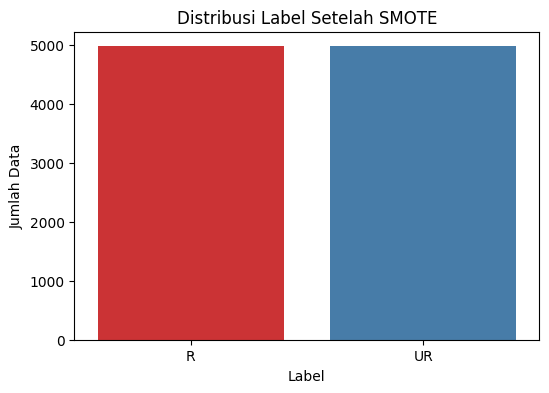

In [25]:
# Visualisasi setelah SMOTE
label_counts_bal = df_balanced['label'].value_counts().sort_index()
label_names_bal = label_encoder.inverse_transform(label_counts_bal.index)
plt.figure(figsize=(6, 4))
sns.barplot(x=label_names_bal, y=label_counts_bal.values, palette='Set1')
plt.title("Distribusi Label Setelah SMOTE")
plt.xlabel("Label")
plt.ylabel("Jumlah Data")
plt.show()

In [26]:
# === Custom Dataset ===
class TextDataset(Dataset):
    def __init__(self, input_ids, labels):
        self.input_ids = input_ids
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids': torch.tensor(self.input_ids[idx], dtype=torch.long),
            'attention_mask': torch.tensor([1]*len(self.input_ids[idx]), dtype=torch.long),  # asumsi padding full
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

In [27]:
# === Dataset dan Split ===
X_train, X_val, y_train, y_val = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled
)
train_dataset = TextDataset(X_train, y_train)
val_dataset = TextDataset(X_val, y_val)

In [12]:
# === Training Arguments ===
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    warmup_steps=50,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=10,
    evaluation_strategy="epoch",
    save_strategy="epoch"
)


c:\Users\Titania\AppData\Local\Programs\Python\Python310\lib\site-packages\transformers\training_args.py:1474: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
# import torch
# print(torch.cuda.is_available())  # True kalau kamu pakai GPU
# print(torch.device("cuda" if torch.cuda.is_available() else "cpu"))


False
cpu


In [ ]:
# === Load dan tune Model ===
model = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-multilingual-cased',
    num_labels=2
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [15]:
# === Trainer ===
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset
)

# === Training ===
trainer.train()


  0%|          | 0/2985 [00:00<?, ?it/s]c:\Users\Titania\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
  0%|          | 10/2985 [00:32<2:31:36,  3.06s/it]

{'loss': 0.6882, 'grad_norm': 2.7245609760284424, 'learning_rate': 1e-05, 'epoch': 0.01}


  1%|          | 20/2985 [01:03<2:29:01,  3.02s/it]

{'loss': 0.6487, 'grad_norm': 3.361243486404419, 'learning_rate': 2e-05, 'epoch': 0.02}


  1%|          | 30/2985 [01:33<2:34:23,  3.13s/it]

...

                                                     
100%|██████████| 2985/2985 [3:23:07<00:00,  3.14s/it]

{'eval_loss': 0.4521505832672119, 'eval_runtime': 128.3302, 'eval_samples_per_second': 15.507, 'eval_steps_per_second': 0.974, 'epoch': 3.0}


100%|██████████| 2985/2985 [3:23:13<00:00,  4.08s/it]

{'train_runtime': 12193.0638, 'train_samples_per_second': 1.958, 'train_steps_per_second': 0.245, 'train_loss': 0.4654561241667474, 'epoch': 3.0}


TrainOutput(global_step=2985, training_loss=0.4654561241667474, metrics={'train_runtime': 12193.0638, 'train_samples_per_second': 1.958, 'train_steps_per_second': 0.245, 'total_flos': 630192951074880.0, 'train_loss': 0.4654561241667474, 'epoch': 3.0})

In [ ]:
# Simpan model
trainer.save_model("model with smote")

# Simpan tokenizer
tokenizer.save_pretrained("model with smote tokenizer")

## **Evaluasi**

In [28]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import joblib

tokenizer = AutoTokenizer.from_pretrained("model with smote tokenizer")
model = AutoModelForSequenceClassification.from_pretrained("model with smote")
label_encoder = joblib.load("label_encoder.pkl")


In [29]:
X_resampled, y_resampled = smote.fit_resample(X_tokenized.tolist(), y.tolist())

In [30]:
X_train, X_val, y_train, y_val = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled
)

In [31]:
import torch
from torch.utils.data import Dataset

X_val_tokenized = tokenizer(
    list(tokenizer.batch_decode(X_val, skip_special_tokens=True)),
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors='pt'
)['input_ids']

class TextDataset(Dataset):
    def __init__(self, input_ids, labels):
        self.input_ids = input_ids
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids': self.input_ids[idx],
            'attention_mask': torch.ones_like(self.input_ids[idx]),  # simple mask
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

val_dataset = TextDataset(X_val_tokenized, y_val)


In [32]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
import numpy as np
from sklearn.metrics import classification_report

model = AutoModelForSequenceClassification.from_pretrained("model with smote")  # model folder
training_args = TrainingArguments(output_dir="./results_eval", per_device_eval_batch_size=16)

trainer = Trainer(model=model, args=training_args, eval_dataset=val_dataset)

preds = trainer.predict(val_dataset)
y_pred = np.argmax(preds.predictions, axis=1)

print(classification_report(y_val, y_pred, target_names=label_encoder.classes_))


c:\Users\Titania\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
100%|██████████| 125/125 [01:23<00:00,  1.50it/s]

              precision    recall  f1-score   support

           R       0.73      0.94      0.82       995
          UR       0.91      0.65      0.76       995

    accuracy                           0.79      1990
   macro avg       0.82      0.79      0.79      1990
weighted avg       0.82      0.79      0.79      1990



In [33]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer

# Load tokenizer dan model dari folder hasil simpanan
tokenizer = AutoTokenizer.from_pretrained("model with smote tokenizer")
model = AutoModelForSequenceClassification.from_pretrained("model with smote")


In [ ]:
# def predict_reason(texts):
#     # Step 1: cleaning
#     def clean_text(text):
#         if pd.isna(text):
#             return ""
#         text = text.lower()
#         text = re.sub(r'[^a-zA-Z\s]', '', text)
#         text = text.replace('eoc', 'end of contract')
#         text = text.replace('thd', 'terhadap')
#         text = text.replace('ybs', 'yang bersangkutan')
#         return text.strip()

#     cleaned = [clean_text(t) for t in texts]

#     # Step 2: tokenisasi
#     inputs = tokenizer(
#         cleaned,
#         padding=True,
#         truncation=True,
#         max_length=128,
#         return_tensors='pt'
#     )

#     # Step 3: prediksi
#     model.eval()
#     with torch.no_grad():
#         outputs = model(**inputs)
#         preds = torch.argmax(outputs.logits, dim=1).numpy()

#     # Step 4: decode label
#     labels = label_encoder.inverse_transform(preds)

#     # Step 5: tampilkan hasil
#     for ori, label in zip(texts, labels):
#         print(f"'{ori}' → Prediksi: {label}")


In [ ]:
# # Tokenizer akan mengubah clean_text jadi input_ids lagi
# X_val_tokenized = tokenizer(
#     list(X_val),
#     padding=True,
#     truncation=True,
#     max_length=128,
#     return_tensors='pt'
# )['input_ids']

# # Siapkan custom dataset lagi
# class TextDataset(Dataset):
#     def __init__(self, input_ids, labels):
#         self.input_ids = input_ids
#         self.labels = labels

#     def __len__(self):
#         return len(self.labels)

#     def __getitem__(self, idx):
#         return {
#             'input_ids': torch.tensor(self.input_ids[idx], dtype=torch.long),
#             'attention_mask': torch.tensor([1]*len(self.input_ids[idx]), dtype=torch.long),
#             'labels': torch.tensor(self.labels[idx], dtype=torch.long)
#         }

# val_dataset = TextDataset(X_val_tokenized.tolist(), y_val)


In [ ]:
# from transformers import BertForSequenceClassification, Trainer

# checkpoints = [
#     "saved_model/checkpoint-500",
#     "saved_model/checkpoint-1000",
#     "saved_model/checkpoint-1500",
#     # dst...
# ]

# for ckpt in checkpoints:
#     try:
#         model = BertForSequenceClassification.from_pretrained(ckpt)
#         trainer = Trainer(model=model, args=training_args)
#         results = trainer.evaluate(eval_dataset=val_dataset)
#         print(f"{ckpt} => {results}")
#     except Exception as e:
#         print(f"Failed to load {ckpt}: {e}")


Failed to load saved_model/checkpoint-500: saved_model/checkpoint-500 is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permission to this repo either by logging in with `huggingface-cli login` or by passing `token=<your_token>`
Failed to load saved_model/checkpoint-1000: saved_model/checkpoint-1000 is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permission to this repo either by logging in with `huggingface-cli login` or by passing `token=<your_token>`
Failed to load saved_model/checkpoint-1500: saved_model/checkpoint-1500 is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permission to this repo either by logging in with `huggingface-cli log

In [ ]:
# import os

# checkpoints = os.listdir("saved_model")
# print(checkpoints)


['config.json', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin', 'vocab.txt']


In [ ]:
# from transformers import Trainer

# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=train_dataset,
#     eval_dataset=val_dataset
# )


In [ ]:
# training_args = TrainingArguments(
#     output_dir='./results',
#     num_train_epochs=3,
#     per_device_train_batch_size=8,
#     per_device_eval_batch_size=16,
#     warmup_steps=50,
#     weight_decay=0.01,
#     logging_dir='./logs',
#     logging_steps=10,
#     evaluation_strategy="steps",     # <- samakan
#     save_strategy="steps",           # <- samakan
#     eval_steps=500,                  # <- evaluasi tiap 500 langkah
#     save_steps=500,                  # <- simpan tiap 500 langkah
#     load_best_model_at_end=True,
#     metric_for_best_model="eval_loss"
# )


In [ ]:
# trainer.train(resume_from_checkpoint=True)

In [ ]:
# import os

# # Ganti dengan path output_dir dari training_args kamu
# checkpoint_dir = "./results"

# # Cek semua subfolder checkpoint
# checkpoints = [os.path.join(checkpoint_dir, d) for d in os.listdir(checkpoint_dir) if d.startswith("checkpoint-")]
# print("Tersedia checkpoint:", checkpoints)


Tersedia checkpoint: ['./results\\checkpoint-1000', './results\\checkpoint-1500', './results\\checkpoint-2000', './results\\checkpoint-2016', './results\\checkpoint-500']


In [ ]:
# training_args = TrainingArguments(
#     output_dir='./results',
#     ...
#     save_strategy="steps",
#     save_steps=500,  # simpan tiap 500 step
#     logging_steps=50,
# )


In [ ]:
# trainer.train(resume_from_checkpoint="./results/checkpoint-2016")

In [ ]:
# import os

# # Ganti dengan path output_dir dari training_args kamu
# checkpoint_dir = "./results"

# # Cek semua subfolder checkpoint
# checkpoints = [os.path.join(checkpoint_dir, d) for d in os.listdir(checkpoint_dir) if d.startswith("checkpoint-")]
# print("Tersedia checkpoint:", checkpoints)


In [ ]:
# # === Model ===
# model = AutoModelForSequenceClassification.from_pretrained(
#     'bert-base-multilingual-cased',
#     num_labels=2
# )

# # === Trainer ===
# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=train_dataset,
#     eval_dataset=val_dataset
# )


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# model = AutoModelForSequenceClassification.from_pretrained(
#     'bert-base-multilingual-cased',
#     num_labels=2  # Layer ini ditambahkan dan akan dilatih dari nol
# )

# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=train_dataset,
#     eval_dataset=val_dataset
# )

# trainer.train()  # Wajib dilakukan agar classifier belajar


In [ ]:
# # === Focal Loss Class ===
# class FocalLoss(nn.Module):
#     def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
#         super(FocalLoss, self).__init__()
#         self.alpha = alpha
#         self.gamma = gamma
#         self.reduction = reduction
#     def forward(self, inputs, targets):
#         ce_loss = nn.functional.cross_entropy(inputs, targets, reduction='none', weight=self.alpha)
#         pt = torch.exp(-ce_loss)
#         focal_loss = (1 - pt) ** self.gamma * ce_loss
#         if self.reduction == 'mean':
#             return focal_loss.mean()
#         elif self.reduction == 'sum':
#             return focal_loss.sum()
#         else:
#             return focal_loss

In [ ]:
# # === Custom Trainer dengan Focal Loss ===
# class FocalLossTrainer(Trainer):
#     def __init__(self, class_weights=None, *args, **kwargs):
#         super().__init__(*args, **kwargs)
#         device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#         self.loss_fct = FocalLoss(alpha=class_weights.to(device), gamma=2.0)
#     def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
#         labels = inputs.pop("labels")
#         outputs = model(**inputs)
#         logits = outputs.logits
#         loss = self.loss_fct(logits, labels)
#         return (loss, outputs) if return_outputs else loss


In [17]:
pip uninstall transformers

^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
pip install transformers==4.41.2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import transformers
print(transformers.__version__)

c:\Users\Titania\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4.41.2


In [34]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from transformers import TrainingArguments


In [ ]:
# training_args = TrainingArguments(
#     output_dir='./results',
#     num_train_epochs=3,
#     per_device_train_batch_size=8,
#     per_device_eval_batch_size=16,
#     warmup_steps=50,
#     weight_decay=0.01,
#     do_eval=True,
#     logging_dir='./logs',
#     logging_steps=10,
#     evaluation_strategy="epoch",
#     save_strategy="epoch"
# )


In [35]:
def clean_text(text):
    if pd.isna(text):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.replace('eoc', 'end of contract')
    text = text.replace('thd', 'terhadap')
    text = text.replace('ybs', 'yang bersangkutan')
    return text.strip()

def predict_reason(texts):
    cleaned = [clean_text(t) for t in texts]

    inputs = tokenizer(
        cleaned,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors='pt'
    )

    if 'token_type_ids' in inputs:
        del inputs['token_type_ids']

    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        preds = torch.argmax(outputs.logits, dim=1).numpy()

    labels = label_encoder.inverse_transform(preds)

    for ori, label in zip(texts, labels):
        print(f"'{ori}' → Prediksi: {label}")


## **Percobaan Prediksi**

In [36]:
predict_reason([
    "KERJAAN TERLALU BERAT",
    "buka usaha ",
    "kesehatan dan sakit",
    "fraud memakai uang kantor untuk kepentingan pribadi",
    "PHK",
    "FRAUD, JUMLAH BARANG YANG DIKIRIM TIDAK SESUAI (SENGAJA)"

])


'KERJAAN TERLALU BERAT' → Prediksi: R
'buka usaha ' → Prediksi: R
'kesehatan dan sakit' → Prediksi: R
'fraud memakai uang kantor untuk kepentingan pribadi' → Prediksi: UR
'PHK' → Prediksi: UR
'FRAUD, JUMLAH BARANG YANG DIKIRIM TIDAK SESUAI (SENGAJA)' → Prediksi: UR


## **Prediksi File**

In [18]:
pd. read_excel('D:\dirty work\data resign.xlsx')

,,REGIONAL,CABANG,NIK,NAMA,TMK,RESIGN DATE,JABATAN,LOKASI KERJA,DIVISI,...,ATASAN LANGSUNG,KATEGORI ALASAN RESIGN,KETERANGAN ALASAN RESIGN/MUTASI BY EXIT INTERVIEW,STATUS KEPEGAWAIAN,PT,DIGANTIKAN/TIDAK,NAMA PENGGANTI,REPLACEMENT DATE,STATUS PENGGANTI,REMARKS
0,1.0,EJ,LATUBO,MRP0001810,AHMAD FAUZI,2024-05-15 00:00:00,2024-07-02,SR HFS,SINGGAHAN,P&G,...,EKO SAMPURNO,Vol-Masalah Keluarga,Mendadak ikut saudara kerja di kalimantan,KONTRAK,MRP,Digantikan,TEGUH BUDI SANTOSO,2024-07-06,NEW HIRE-OS,NaN
1,2.0,EJ,JEMBER,MRP0001836,DEDY CATUR SETYAWAN,2024-06-07 00:00:00,2024-07-03,DELIVERY,BANYUWANGI,P&G,...,WIDODO,Vol-Tidak Cocok Dengan Budaya Kerja,Merasa kurang kerja sama dengan sesama delivery,KONTRAK,MRP,Digantikan,SISWANTO,2024-07-04,NEW HIRE-OS,NaN
2,3.0,EJ,KEDIRI,BCP0009405,MOCH. AGUNG ADI AFRIAN,1994-10-01 00:00:00,2024-07-06,REGIONAL SALES MANAGER,KEDIRI,P&G,...,AGUS SAIFUL ANAM,Inv-Berakhirnya Kontrak Kerja,Pensiun,TETAP,BCP,Digantikan,DAVID KURNIAWAN,2024-07-01,INTERNAL-BCP,NaN
3,NaN,BNT,LOMBOK,VAL0001997,DIMAS WAHYUDI,2024-05-21 00:00:00,2024-07-13,MD HFS,PRAYA,P&G,...,A.A. GEDE YUDA WIRANTARA,Vol-Masalah Keluarga,Pada awalnya ijin terus ijin sakit. ada masala...,KONTRAK,VALDO,Digantikan,TAUFIK HIDAYAT,2024-07-16,NEW HIRE-OS,NaN
4,NaN,EJ,KEDIRI,20101115HD,HAPPY DWI EFFENDI,2010-11-15 00:00:00,2024-07-16,COLLECTOR,JOMBANG,NL,...,ARIK MINTOROSASI,Meninggal dunia,Meninggal dunia,TETAP,BCP,Digantikan,PUNDRA WAHYU SATRIA,2024-07-29,NEW HIRE-BCP,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1312,NaN,SLW,MANADO,KAS0000087,JEINI BOHAM,2025-03-12 00:00:00,2025-04-14,SR MIX,MANADO,SKINTIFIC,...,TAKDIR RUDY MULYA,Inv-Pelanggaran Masalah Kedisiplinan,MANGKIR (SUPA),KONTRAK,KAS,Digantikan,CHRISTIANTO JOSEPH MINGGU,2025-04-07,NEW HIRE - KAS,NaN
1313,NaN,SLW,POSO,BCP0008956,REZKI MULYA UTAMI,2025-01-02 00:00:00,2025-03-31,KASIR,POSO,P&G,...,MUHAMMAD ASRI,Inv-Berakhirnya Kontrak Kerja,MENOLAK REHIRE (LULUS PNS),KONTRAK,BCP,Digantikan,HANIFA R MALIKI,2025-03-21,INTERNAL BCP,NEW HIRE BCP
1314,NaN,SLW,MANADO,KAS0000072,KHAIRUL KASIM,2025-01-02 00:00:00,2025-04-19,SR MIX,MANADO,LOREAL,...,TAKDIR RUDY MULYA,Vol-Masalah Keluarga,SELISIH PAHAM DENGAN TETANGGA DAN MENGHARUSKAN...,KONTRAK,KAS,Digantikan,GRATCIA IRNOVRAHLIA AREROS,2025-05-06,NEW HIRE - KAS,NaN
1315,NaN,SLW,PALOPO,BCP0009605,"ROMI DARJAT, S.PD",2025-01-02 00:00:00,2025-04-12,SERVICE QA STAFF,PALOPO,P&G,...,FAIS FACHRUR ROZY,Vol-Masalah Kesehatan,Kondisi kesehatan ingin fokus berobat,KONTRAK,BCP,Digantikan,Novandy Ikhsan Putra Ely,2025-04-14,NEW HIRE BCP,NaN


In [1]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import joblib

# Load tokenizer dan model dari folder
tokenizer = AutoTokenizer.from_pretrained("model with smote tokenizer")
model = AutoModelForSequenceClassification.from_pretrained("model with smote")

# Load label encoder
label_encoder = joblib.load("label_encoder.pkl")

# Buat trainer kosong untuk prediksi
training_args = TrainingArguments(output_dir="./temp", per_device_eval_batch_size=16)
trainer = Trainer(model=model, args=training_args)


c:\Users\Titania\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd
import re
import torch
from torch.utils.data import Dataset
import numpy as np

def predict_from_file(file_path, text_column='KETERANGAN ALASAN RESIGN/MUTASI BY EXIT INTERVIEW', output_path='hasil_sentimen.xlsx'):
    # === 1. Load file Excel ===
    df_input = pd.read_excel(file_path)

    # === 2. Clean teks ===
    def clean_text(text):
        if pd.isna(text):
            return ""
        text = text.lower()
        text = re.sub(r'[^a-zA-Z\s]', '', text)
        text = text.replace('eoc', 'end of contract')
        text = text.replace('thd', 'terhadap')
        text = text.replace('ybs', 'yang bersangkutan')
        return text.strip()

    df_input['clean_text'] = df_input[text_column].apply(clean_text)

    # === 3. Tokenisasi teks ===
    inputs = tokenizer(
        list(df_input['clean_text']),
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors='pt'
    )

    if 'token_type_ids' in inputs:
        del inputs['token_type_ids']

    # === 4. Dummy Dataset
    class PredictDataset(Dataset):
        def __init__(self, input_ids, attention_mask):
            self.input_ids = input_ids
            self.attention_mask = attention_mask

        def __len__(self):
            return len(self.input_ids)

        def __getitem__(self, idx):
            return {
                'input_ids': self.input_ids[idx],
                'attention_mask': self.attention_mask[idx]
            }

    predict_dataset = PredictDataset(inputs['input_ids'], inputs['attention_mask'])

    # === 5. Prediksi
    model.eval()
    predictions = trainer.predict(predict_dataset)
    y_pred = np.argmax(predictions.predictions, axis=1)
    labels = label_encoder.inverse_transform(y_pred)

    # === 6. Mapping ke Sentimen
    sentiment_mapping = {'R': 'Positif', 'UR': 'Negatif'}
    df_input['sentimen'] = [sentiment_mapping.get(lbl, 'Tidak diketahui') for lbl in labels]

    # === 7. Simpan ke file
    df_input.to_excel(output_path, index=False)
    print(f"✔ Hasil disimpan ke: {output_path}")


In [3]:
predict_from_file(r"D:\dirty work\data resign.xlsx")

c:\Users\Titania\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
100%|██████████| 83/83 [01:06<00:00,  1.25it/s]


✔ Hasil disimpan ke: hasil_sentimen.xlsx


In [4]:
pd. read_excel('D:\dirty work\hasil_sentimen.xlsx')

,,REGIONAL,CABANG,NIK,NAMA,TMK,RESIGN DATE,JABATAN,LOKASI KERJA,DIVISI,...,KETERANGAN ALASAN RESIGN/MUTASI BY EXIT INTERVIEW,STATUS KEPEGAWAIAN,PT,DIGANTIKAN/TIDAK,NAMA PENGGANTI,REPLACEMENT DATE,STATUS PENGGANTI,REMARKS,clean_text,sentimen
0,1.0,EJ,LATUBO,MRP0001810,AHMAD FAUZI,2024-05-15 00:00:00,2024-07-02,SR HFS,SINGGAHAN,P&G,...,Mendadak ikut saudara kerja di kalimantan,KONTRAK,MRP,Digantikan,TEGUH BUDI SANTOSO,2024-07-06,NEW HIRE-OS,NaN,mendadak ikut saudara kerja di kalimantan,Positif
1,2.0,EJ,JEMBER,MRP0001836,DEDY CATUR SETYAWAN,2024-06-07 00:00:00,2024-07-03,DELIVERY,BANYUWANGI,P&G,...,Merasa kurang kerja sama dengan sesama delivery,KONTRAK,MRP,Digantikan,SISWANTO,2024-07-04,NEW HIRE-OS,NaN,merasa kurang kerja sama dengan sesama delivery,Positif
2,3.0,EJ,KEDIRI,BCP0009405,MOCH. AGUNG ADI AFRIAN,1994-10-01 00:00:00,2024-07-06,REGIONAL SALES MANAGER,KEDIRI,P&G,...,Pensiun,TETAP,BCP,Digantikan,DAVID KURNIAWAN,2024-07-01,INTERNAL-BCP,NaN,pensiun,Positif
3,NaN,BNT,LOMBOK,VAL0001997,DIMAS WAHYUDI,2024-05-21 00:00:00,2024-07-13,MD HFS,PRAYA,P&G,...,Pada awalnya ijin terus ijin sakit. ada masala...,KONTRAK,VALDO,Digantikan,TAUFIK HIDAYAT,2024-07-16,NEW HIRE-OS,NaN,pada awalnya ijin terus ijin sakit ada masalah...,Positif
4,NaN,EJ,KEDIRI,20101115HD,HAPPY DWI EFFENDI,2010-11-15 00:00:00,2024-07-16,COLLECTOR,JOMBANG,NL,...,Meninggal dunia,TETAP,BCP,Digantikan,PUNDRA WAHYU SATRIA,2024-07-29,NEW HIRE-BCP,NaN,meninggal dunia,Positif
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1312,NaN,SLW,MANADO,KAS0000087,JEINI BOHAM,2025-03-12 00:00:00,2025-04-14,SR MIX,MANADO,SKINTIFIC,...,MANGKIR (SUPA),KONTRAK,KAS,Digantikan,CHRISTIANTO JOSEPH MINGGU,2025-04-07,NEW HIRE - KAS,NaN,mangkir supa,Negatif
1313,NaN,SLW,POSO,BCP0008956,REZKI MULYA UTAMI,2025-01-02 00:00:00,2025-03-31,KASIR,POSO,P&G,...,MENOLAK REHIRE (LULUS PNS),KONTRAK,BCP,Digantikan,HANIFA R MALIKI,2025-03-21,INTERNAL BCP,NEW HIRE BCP,menolak rehire lulus pns,Positif
1314,NaN,SLW,MANADO,KAS0000072,KHAIRUL KASIM,2025-01-02 00:00:00,2025-04-19,SR MIX,MANADO,LOREAL,...,SELISIH PAHAM DENGAN TETANGGA DAN MENGHARUSKAN...,KONTRAK,KAS,Digantikan,GRATCIA IRNOVRAHLIA AREROS,2025-05-06,NEW HIRE - KAS,NaN,selisih paham dengan tetangga dan mengharuskan...,Positif
1315,NaN,SLW,PALOPO,BCP0009605,"ROMI DARJAT, S.PD",2025-01-02 00:00:00,2025-04-12,SERVICE QA STAFF,PALOPO,P&G,...,Kondisi kesehatan ingin fokus berobat,KONTRAK,BCP,Digantikan,Novandy Ikhsan Putra Ely,2025-04-14,NEW HIRE BCP,NaN,kondisi kesehatan ingin fokus berobat,Positif


In [41]:
df = pd.read_excel("D:\\dirty work\\hasil_sentimen.xlsx")
print(df.columns)

Index(['   ', 'REGIONAL', 'CABANG', 'NIK', 'NAMA', 'TMK', 'RESIGN DATE',
       'JABATAN', 'LOKASI KERJA', 'DIVISI', 'FUNGSI', 'ATASAN LANGSUNG',
       'KATEGORI ALASAN RESIGN',
       'KETERANGAN ALASAN RESIGN/MUTASI BY EXIT INTERVIEW',
       'STATUS KEPEGAWAIAN', 'PT', 'DIGANTIKAN/TIDAK', 'NAMA PENGGANTI',
       'REPLACEMENT DATE', 'STATUS PENGGANTI', 'REMARKS', 'clean_text',
       'sentimen'],
      dtype='object')


In [24]:
# Baca data
tn = pd.read_excel(r'D:\dirty work\hasil_sentimen.xlsx')

# Cek jumlah masing-masing sentimen
print(tn['sentimen'].value_counts())

sentimen
Positif    1045
Negatif     272
Name: count, dtype: int64


In [27]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


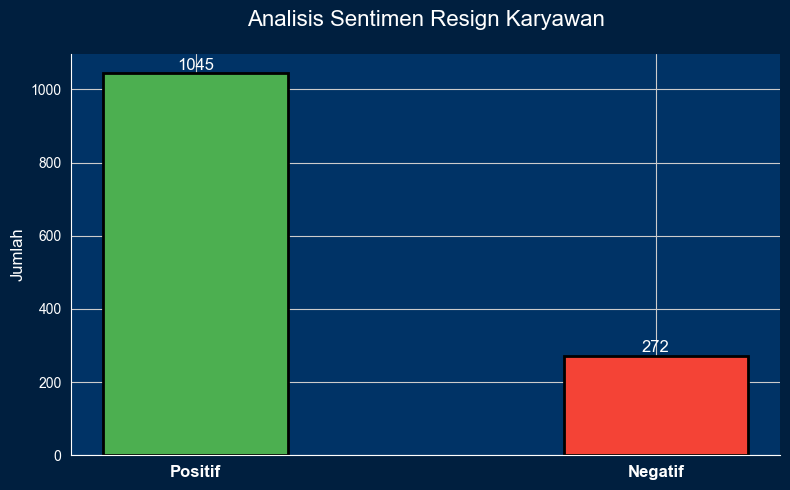

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as patches

# Baca data
df = pd.read_excel('D:\dirty work\hasil_sentimen.xlsx')

# Hitung jumlah per sentimen
counts = df['sentimen'].value_counts()
labels = counts.index.tolist()
values = counts.values.tolist()

# Atur urutan label biar tetap Positif dulu baru Negatif (optional)
if 'Positif' in labels and 'Negatif' in labels:
    labels = ['Positif', 'Negatif']
    values = [counts.get('Positif', 0), counts.get('Negatif', 0)]

# Warna batang dan border
color_map = {
    'Positif': '#4CAF50',  # hijau
    'Negatif': '#F44336',  # merah
}
edge_color = 'black'

# Setup figure dengan background biru gradasi navy
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('#001f3f')
ax.set_facecolor('#003366')

# Bar chart manual
bar_width = 0.4
positions = range(len(labels))

for i, (label, value) in enumerate(zip(labels, values)):
    ax.bar(i, value, width=bar_width, color=color_map[label], edgecolor=edge_color, linewidth=2)

# Customisasi sumbu
ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=12, color='white', fontweight='bold')
ax.set_ylabel("Jumlah", fontsize=12, color='white')
ax.set_title("Analisis Sentimen Resign Karyawan", fontsize=16, color='white', pad=20)

# Label value di atas bar
for i, value in enumerate(values):
    ax.text(i, value + 1, str(value), ha='center', va='bottom', fontsize=12, color='white')

# Hilangkan spines dan grid
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')
ax.tick_params(axis='y', colors='white')
ax.tick_params(axis='x', colors='white')

plt.tight_layout()
plt.show()


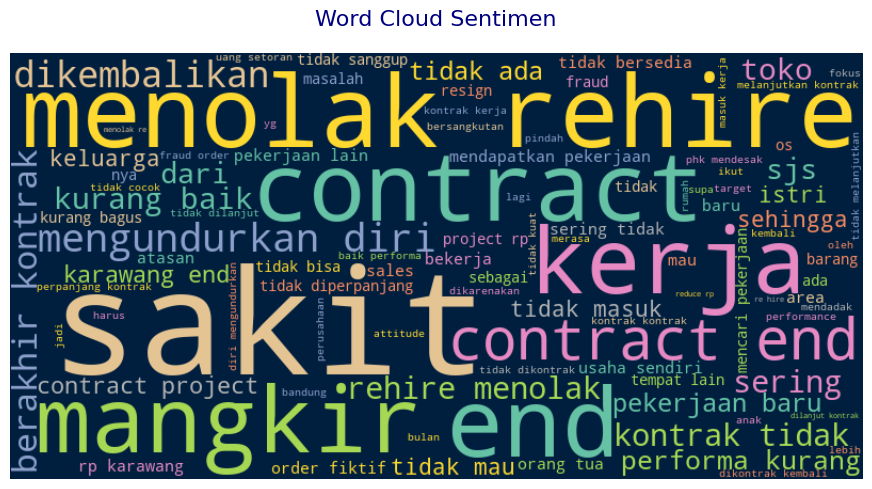

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

# Baca data
df = pd.read_excel('D:\\dirty work\\hasil_sentimen.xlsx')

# Gabungkan semua teks di kolom 'alasan' (ganti jika nama kolom berbeda)
text_data = " ".join(str(teks) for teks in df['clean_text'] if pd.notnull(teks))

# Tambahkan stopwords custom
stopwords = set(STOPWORDS)
stopwords.update(["karena", "yang","dan","di", "ke","untuk", "sudah", "saya","dengan", "ingin", "dapat","rp karawang"])

# Buat WordCloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='#001f3f',  # biru gelap
    colormap='Set2',
    max_words=100,
    contour_color='white',
    contour_width=1,
    stopwords=stopwords
).generate(text_data)

# Tampilkan WordCloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud Sentimen", fontsize=16, color='navy', pad=20)
plt.gca().set_facecolor('#001f3f')  # latar belakang plot
plt.tight_layout()
plt.show()


In [33]:
import pandas as pd
import plotly.graph_objects as go

# Baca data
df = pd.read_excel('D:\\dirty work\\hasil_sentimen.xlsx')

# Ubah semua huruf di kolom 'STATUS KEPEGAWAIAN' jadi kecil
df['STATUS KEPEGAWAIAN'] = df['STATUS KEPEGAWAIAN'].str.lower()

# Hitung jumlah tiap status
status_counts = df['STATUS KEPEGAWAIAN'].value_counts()
labels = status_counts.index.tolist()
values = status_counts.values.tolist()

# Warna-warna yang berbeda
colors = ['#FF5733', '#FFBD33', '#DBFF33', '#33FF57', '#33FFBD', '#337BFF', '#8E44AD', '#2ECC71']

# Buat pie chart
fig = go.Figure(data=[go.Pie(
    labels=labels,
    values=values,
    hole=0.3,  # Membuat efek donat
    pull=[0.05] * len(labels),  # Efek keluar untuk semua irisan
    textinfo='percent+label',
    marker=dict(
        colors=[colors[i % len(colors)] for i in range(len(labels))],
        line=dict(color='black', width=2)
    ),
    opacity=0.85,
    hoverinfo='label+percent',
    rotation=90
)])

# Atur layout dan judul besar
fig.update_layout(
    title=dict(
        text="Distribusi Status Kepegawaian",
        font=dict(size=24),  # Ukuran judul diperbesar
        x=0.5  # Posisi tengah
    ),
    paper_bgcolor='#001f3f',  # Background navy
    font=dict(color='white'),
    height=700,
    width=600,
    legend=dict(title='Status', orientation='v')
)

# Tampilkan
fig.show()


In [40]:
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px

# 1. Baca data
df = pd.read_excel('D:\\dirty work\\hasil_sentimen.xlsx')

# 2. Pastikan lowercase
df['clean_text'] = df['clean_text'].str.lower()
df['STATUS KEPEGAWAIAN'] = df['STATUS KEPEGAWAIAN'].str.lower()

# 3. Filter baris yang mengandung kata "mangkir"
df_mangkir = df[df['clean_text'].str.contains("mangkir", na=False)]

# 4. Hitung jumlah per status kepegawaian
status_counts = df_mangkir['STATUS KEPEGAWAIAN'].value_counts()
labels = status_counts.index.tolist()
values = status_counts.values.tolist()

# 5. Pie chart interaktif dengan gradasi dan efek 3D donat
fig = go.Figure(data=[go.Pie(
    labels=labels,
    values=values,
    hole=0.3,
    textinfo='label+percent',
    pull=[0.07]*len(labels),
    marker=dict(
        colors=px.colors.sequential.Plasma,
        line=dict(color='white', width=2)
    )
)])

# 6. Layout: judul besar, posisi tengah, latar navy
fig.update_layout(
    title=dict(
        text="Distribusi Status Kepegawaian yang Alasan Resign-nya 'Mangkir'",
        font=dict(size=15),
        x=0.5  # Pusatkan judul
    ),
    paper_bgcolor='#001f3f',
    font=dict(color='white'),
    height=500,
    width=500
)

fig.show()


In [6]:
import pandas as pd

# 1. Baca data
df = pd.read_excel('D:\\dirty work\\hasil_sentimen.xlsx')

# 2. Pastikan lowercase
df['clean_text'] = df['clean_text'].str.lower()
df['STATUS KEPEGAWAIAN'] = df['STATUS KEPEGAWAIAN'].str.lower()
df['DIVISI'] = df['DIVISI'].str.upper()  # Biar divisinya rapi & konsisten

# 3. Filter: hanya yang statusnya 'kontrak' dan alasan resign-nya mengandung 'mangkir'
df_kontrak_mangkir = df[
    (df['STATUS KEPEGAWAIAN'] == 'kontrak') &
    (df['clean_text'].str.contains("mangkir", na=False))
]

# 4. Hitung jumlah per divisi
divisi_terbanyak = df_kontrak_mangkir['DIVISI'].value_counts().sort_values(ascending=False)

# 5. Tampilkan hasil
print("📊 Divisi dengan Jumlah Pegawai KONTRAK yang Resign karena 'Mangkir':\n")
print(divisi_terbanyak)


📊 Divisi dengan Jumlah Pegawai KONTRAK yang Resign karena 'Mangkir':

DIVISI
P&G          43
RB            3
SIGNIFY       2
SKINTIFIC     2
OMEGA         1
IDP           1
Name: count, dtype: int64


In [15]:
import pandas as pd
import plotly.express as px

# 1. Baca data
df = pd.read_excel('D:\\dirty work\\hasil_sentimen.xlsx')

# 2. Pastikan format
df['clean_text'] = df['clean_text'].str.lower()
df['STATUS KEPEGAWAIAN'] = df['STATUS KEPEGAWAIAN'].str.lower()
df['DIVISI'] = df['DIVISI'].str.upper()

# 3. Filter: kontrak + mangkir
df_kontrak_mangkir = df[
    (df['STATUS KEPEGAWAIAN'] == 'kontrak') &
    (df['clean_text'].str.contains("mangkir", na=False))
]

# 4. Hitung jumlah per divisi
divisi_terbanyak = df_kontrak_mangkir['DIVISI'].value_counts().reset_index()
divisi_terbanyak.columns = ['DIVISI', 'count']

# 5. Treemap dengan marks di visual
fig = px.treemap(
    divisi_terbanyak,
    path=['DIVISI'],
    values='count',
    color='count',
    color_continuous_scale='Plasma',
    title="Treemap Divisi Pegawai Kontrak yang Resign karena 'Mangkir'",
)

# 6. Layout dan label styling
fig.update_traces(
    texttemplate='%{label}<br>%{value} orang',  # label + nilai langsung di visual
    textfont=dict(size=14, color='white'),
    hovertemplate='<b>Divisi:</b> %{label}<br><b>Jumlah:</b> %{value} orang<extra></extra>'
)

fig.update_layout(
    paper_bgcolor='#001f3f',
    plot_bgcolor='#001f3f',
    font_color='white',
    title_x=0.5,
    margin=dict(t=50, l=10, r=10, b=10)
)

fig.show()


In [43]:
import pandas as pd

# 1. Baca data
df = pd.read_excel("D:\\dirty work\\hasil_sentimen.xlsx")

# 2. Pastikan kolom tanggal dalam format datetime
df['RESIGN DATE'] = pd.to_datetime(df['RESIGN DATE'], errors='coerce')
df['REPLACEMENT DATE'] = pd.to_datetime(df['REPLACEMENT DATE'], errors='coerce')

# 3. Filter hanya baris yang benar-benar digantikan
df_ganti = df[df['DIGANTIKAN/TIDAK'].str.lower() == 'digantikan']

# 4. Hitung selisih hari posisi kosong
df_ganti['selisih_hari_kosong'] = (df_ganti['REPLACEMENT DATE'] - df_ganti['RESIGN DATE']).dt.days

# 5. Buang data negatif atau null
df_ganti = df_ganti[df_ganti['selisih_hari_kosong'].notnull() & (df_ganti['selisih_hari_kosong'] >= 0)]

# 6. Hitung rata-rata per divisi
rata2_per_divisi = df_ganti.groupby('DIVISI')['selisih_hari_kosong'].mean().round(2).sort_values(ascending=False)

# 7. Tampilkan hasil
print("📊 Rata-rata Hari Posisi Kosong Sebelum Digantikan per DIVISI:\n")
print(rata2_per_divisi)


📊 Rata-rata Hari Posisi Kosong Sebelum Digantikan per DIVISI:

DIVISI
SKINTIFIC    16.83
LOREAL       12.00
APL          10.00
IDP           9.75
PHC           7.25
VERSUNI       7.12
NFI           5.67
DR SOAP       5.50
P&G           4.97
SIGNIFY       4.18
RB            3.89
BOKS          3.00
NL            2.50
NUTRIFOOD     2.00
SCHNEIDER     2.00
UNIFAM        2.00
UNIFAM        2.00
STT           1.00
OMEGA         0.00
Name: selisih_hari_kosong, dtype: float64


C:\Users\Titania\AppData\Local\Temp\ipykernel_13864\8667893.py:14: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

